In [1]:
%pip install --no-cache-dir --force-reinstall numpy==2.2.6

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 161.1 MB/s  0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.2.6
    Uninstalling numpy-2.2.6:
      Successfully uninstalled numpy-2.2.6
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
landingai 0.3.49 requires numpy<2.0.0,>=1.21.0, but you have numpy 2.2.6 which is incompatible.
spacy 3.8.18 requires click<9.0.0,>=8.2.1, but you have click 8.1.8 which is incompatible.


In [1]:
import numpy as np
print("NumPy:", np.__version__)

import easyocr
print("EasyOCR imported successfully")

import landingai
print("LandingAI imported successfully")

NumPy: 2.2.6
EasyOCR imported successfully
LandingAI imported successfully


In [2]:
import os
import re
import getpass

from datetime import date
from PIL import Image, ImageDraw
from IPython.display import display, Markdown, Audio
from google.colab import files
from landingai.predict import Predictor

# LandingAI credentials
API_KEY = getpass.getpass("Enter LandingAI API key: ")
ENDPOINT_ID = "cdd7cde5-0ada-43dd-be7a-3d2a098b5221"

# OCR configuration
EASYOCR_LANGUAGES = ["en"]  # Change this to match your label language
DETECTION_THRESHOLD = 0.25
LOW_OCR_CONFIDENCE = 0.50

detector = Predictor(
    endpoint_id=ENDPOINT_ID,
    api_key=API_KEY
)

_easyocr_reader = None

print("LandingAI detector initialized.")

Enter LandingAI API key: ··········
LandingAI detector initialized.


Saving tMtgagRoJ4sTMGN0V8XbV3de2sKeubewMN95WWcAyp2kUNqJfegoE2cnTF_7LPxt9z_1Qz06JU2vCSKRhq1DrDS8e4G6nZ9eIfloYeTpKXHx3riJRufOSfG394CpNGDfs_bUyJUIURdFGfvcUmRjxNYgXGo3Ly5LKs3f0oZfnQGRdGd5B4-dNVtYcTcGMMg4.jpg to tMtgagRoJ4sTMGN0V8XbV3de2sKeubewMN95WWcAyp2kUNqJfegoE2cnTF_7LPxt9z_1Qz06JU2vCSKRhq1DrDS8e4G6nZ9eIfloYeTpKXHx3riJRufOSfG394CpNGDfs_bUyJUIURdFGfvcUmRjxNYgXGo3Ly5LKs3f0oZfnQGRdGd5B4-dNVtYcTcGMMg4.jpg


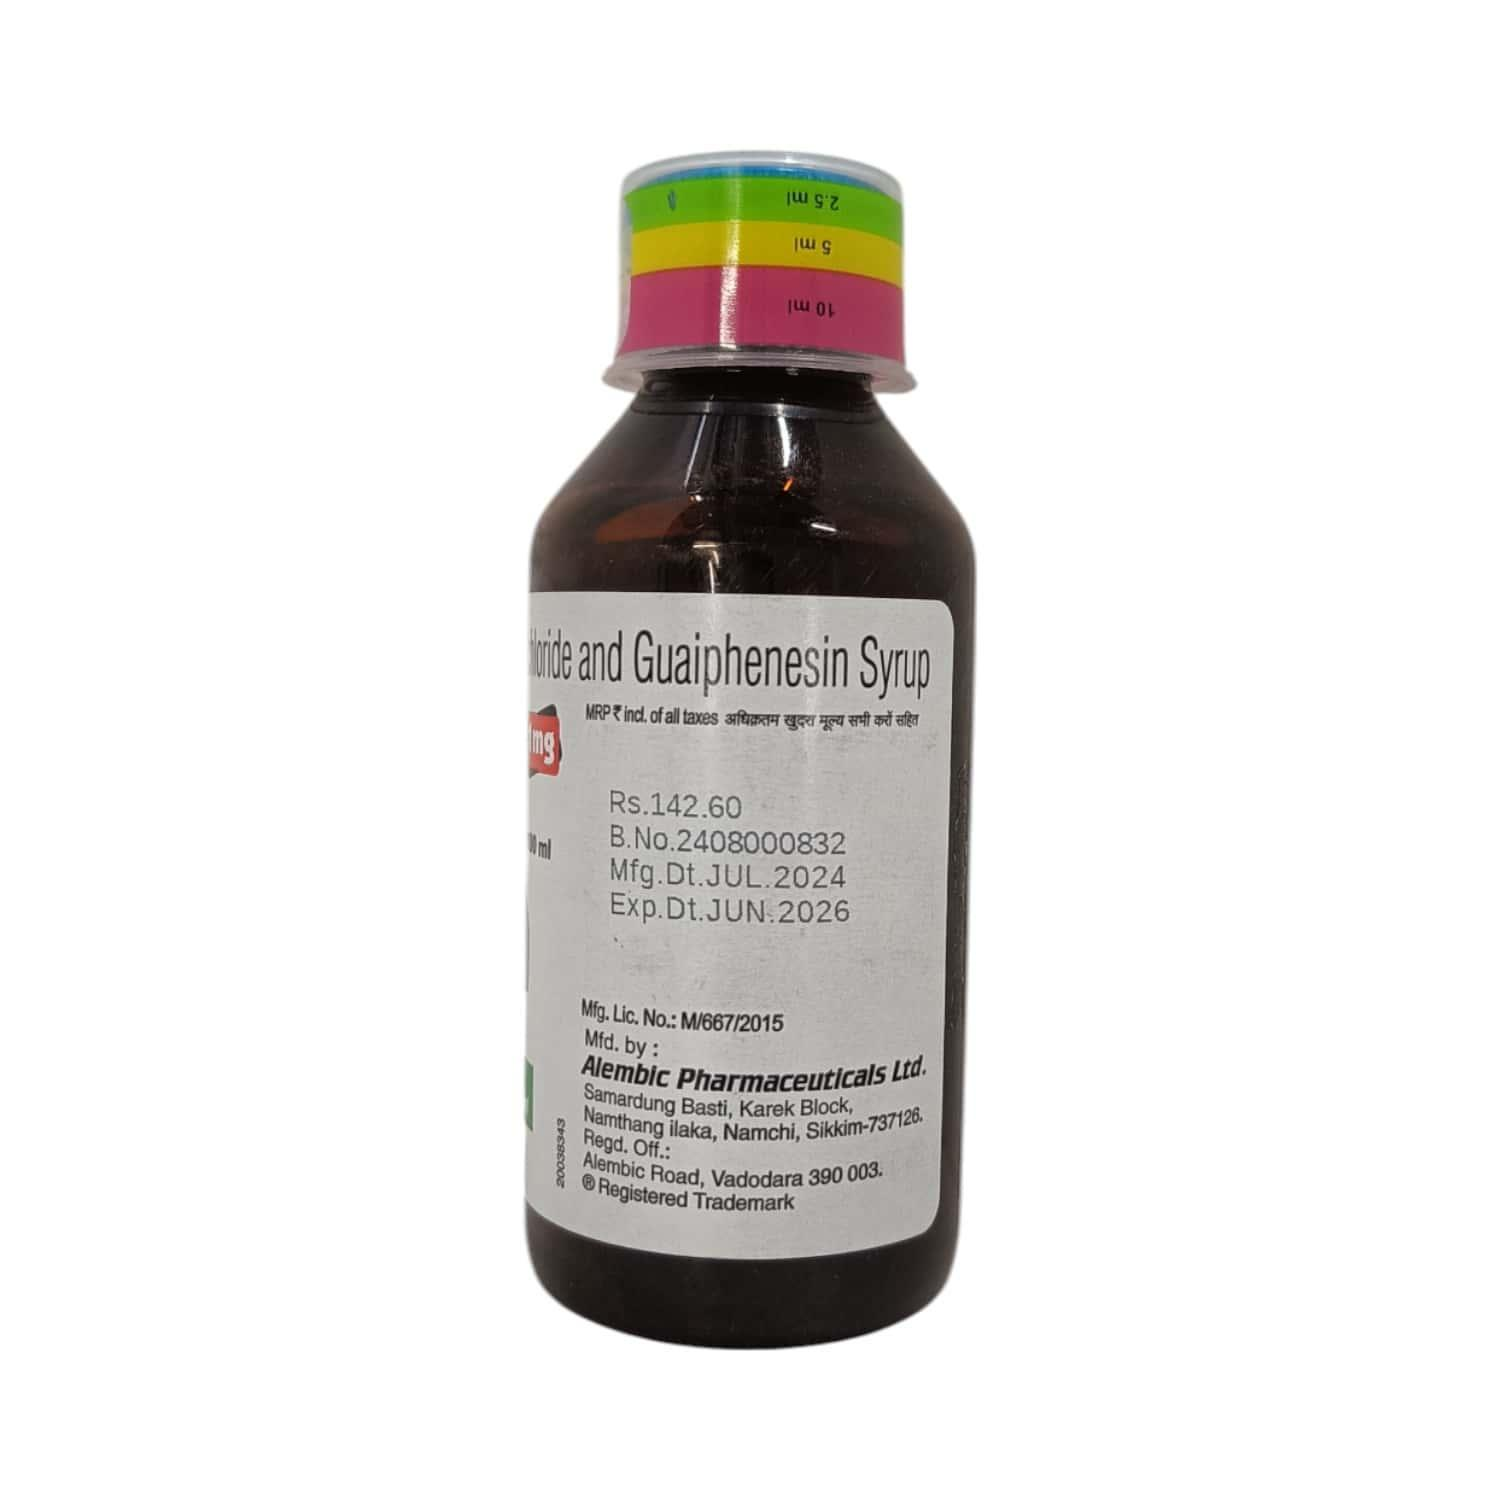

Image loaded: tMtgagRoJ4sTMGN0V8XbV3de2sKeubewMN95WWcAyp2kUNqJfegoE2cnTF_7LPxt9z_1Qz06JU2vCSKRhq1DrDS8e4G6nZ9eIfloYeTpKXHx3riJRufOSfG394CpNGDfs_bUyJUIURdFGfvcUmRjxNYgXGo3Ly5LKs3f0oZfnQGRdGd5B4-dNVtYcTcGMMg4.jpg


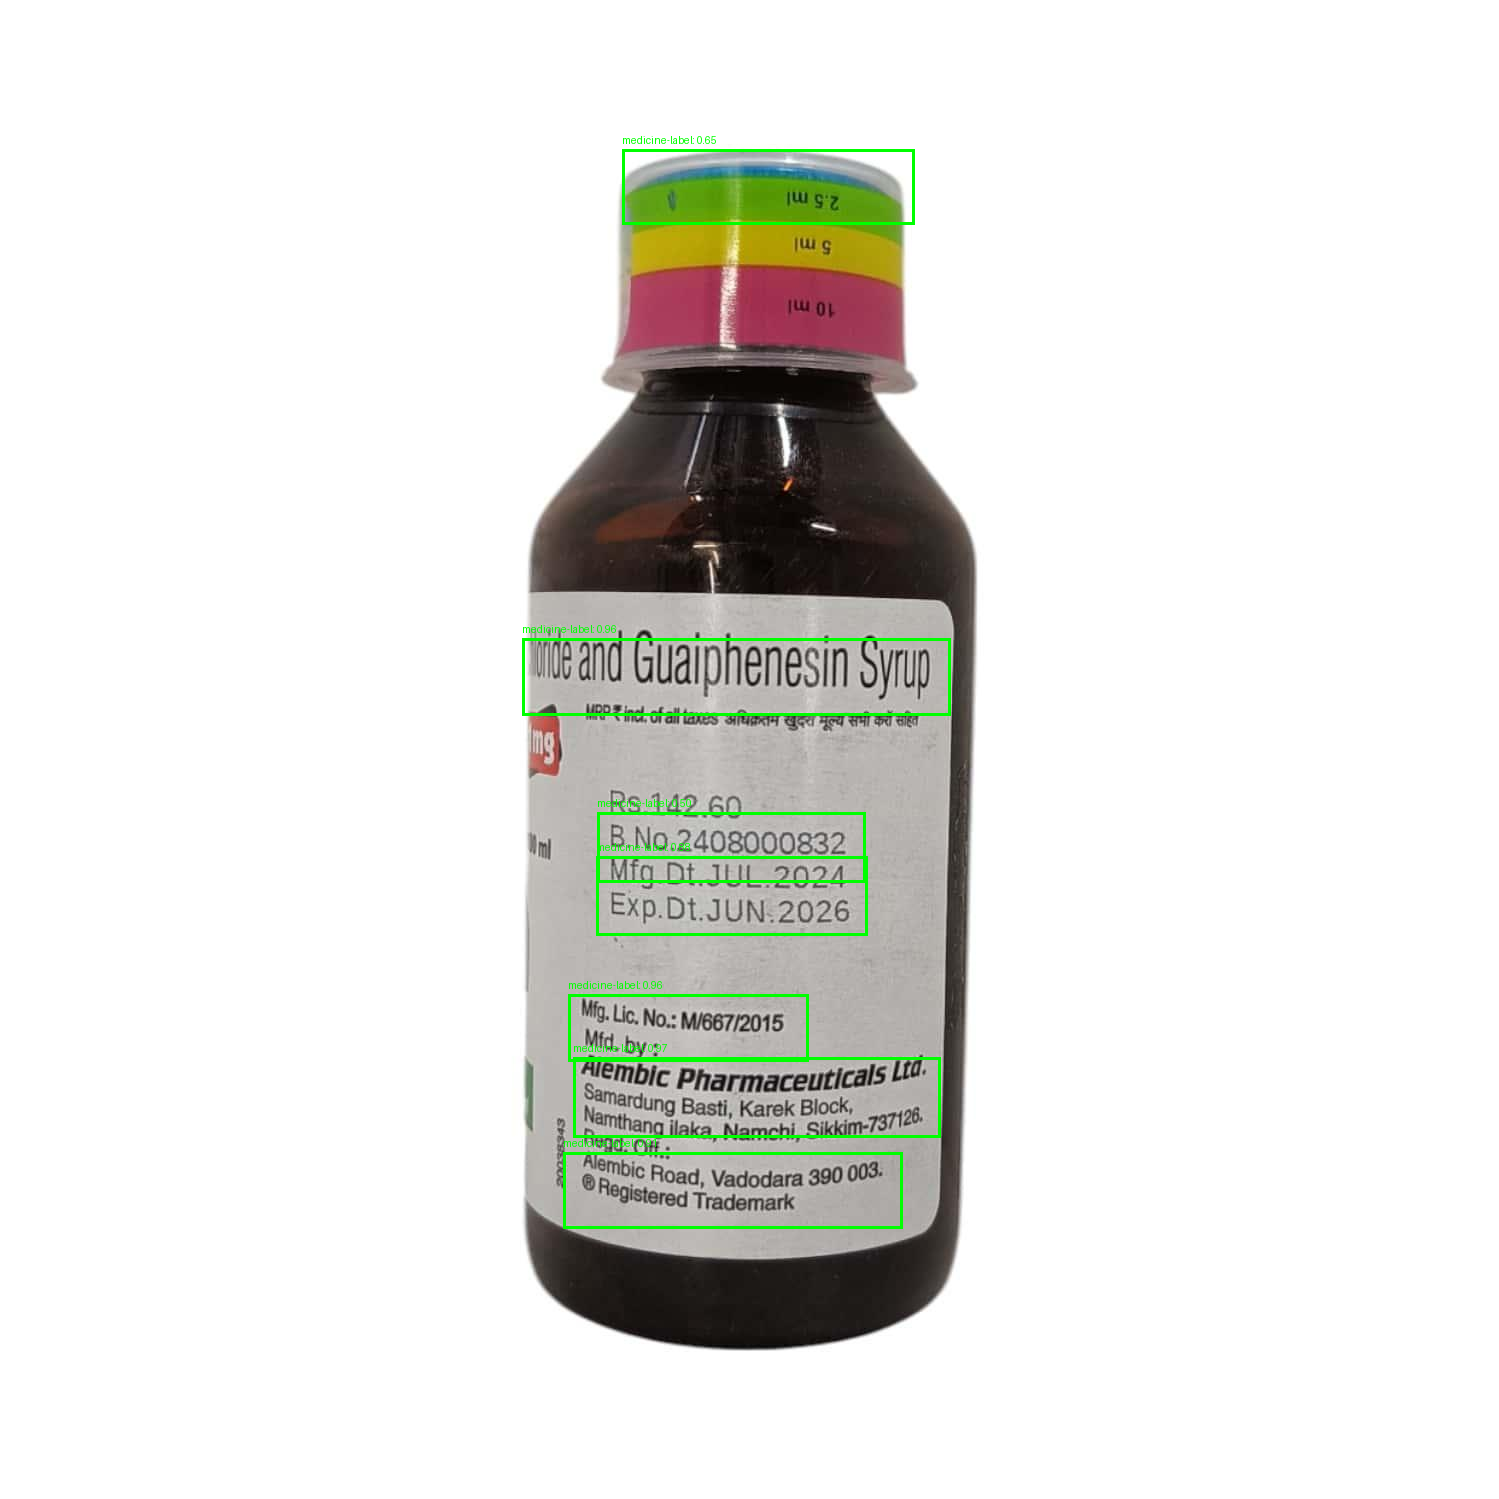

Detected regions: 7


In [3]:
uploaded = files.upload()

IMAGE_PATH = next(iter(uploaded.keys()))

image = Image.open(IMAGE_PATH).convert("RGB")

display(image)
print("Image loaded:", IMAGE_PATH)


def detect_label_regions(image):
    full_region = [
        ("full_label", 1.0, (0, 0, image.width, image.height))
    ]

    try:
        predictions = detector.predict(np.array(image))
    except Exception as e:
        print("Detection failed:", e)
        return full_region

    regions = []

    for p in predictions:
        bbox = getattr(p, "bboxes", None)
        score = float(getattr(p, "score", 0))

        if bbox is None or score < DETECTION_THRESHOLD:
            continue

        x0, y0, x1, y1 = map(int, bbox)

        # Add padding around detected text regions
        pad = 8

        x0 = max(0, x0 - pad)
        y0 = max(0, y0 - pad)
        x1 = min(image.width, x1 + pad)
        y1 = min(image.height, y1 + pad)

        regions.append((
            getattr(p, "label_name", "medicine-label"),
            score,
            (x0, y0, x1, y1)
        ))

    if not regions:
        print("No regions detected. Using the complete image.")
        return full_region

    regions.sort(key=lambda r: (r[2][1], r[2][0]))

    return regions


def draw_regions(image, regions):
    result = image.copy()
    draw = ImageDraw.Draw(result)

    for name, score, (x0, y0, x1, y1) in regions:
        draw.rectangle(
            (x0, y0, x1, y1),
            outline="lime",
            width=3
        )
        draw.text(
            (x0, max(0, y0 - 15)),
            f"{name}: {score:.2f}",
            fill="lime"
        )

    return result


regions = detect_label_regions(image)

display(draw_regions(image, regions))

print("Detected regions:", len(regions))

In [5]:
from PIL import Image

# Initialize EasyOCR
reader = easyocr.Reader(["en"], gpu=False)

ocr_results = []
all_text = []

# Get image dimensions
image_width, image_height = image.size

# Use the full image if no detection regions were found
if not regions:
    regions = [
        ("full_image", 1.0, (0, 0, image_width, image_height))
    ]

print("Running OCR...\n")

for i, region in enumerate(regions):

    label, detection_score, coordinates = region

    x0, y0, x1, y1 = map(int, coordinates)

    # Keep coordinates within image boundaries
    x0 = max(0, min(x0, image_width))
    y0 = max(0, min(y0, image_height))
    x1 = max(0, min(x1, image_width))
    y1 = max(0, min(y1, image_height))

    # Skip invalid regions
    if x1 <= x0 or y1 <= y0:
        continue

    # Crop detected region
    crop = image.crop((x0, y0, x1, y1))

    # Convert crop to NumPy array
    crop_array = np.array(crop.convert("RGB"))

    # Perform OCR
    results = reader.readtext(
        crop_array,
        detail=1,
        paragraph=False
    )

    for bbox, detected_text, confidence in results:

        detected_text = detected_text.strip()

        if not detected_text:
            continue

        ocr_results.append({
            "text": detected_text,
            "score": float(confidence),
            "location": bbox,
            "region": i
        })

        all_text.append(detected_text)

# Combine extracted text
full_text = "\n".join(all_text)

# Display results
print("=" * 50)
print("OCR RESULTS")
print("=" * 50)

if ocr_results:
    for item in ocr_results:
        print(
            f"- {item['text']} "
            f"(Confidence: {item['score']:.2f})"
        )
else:
    print("No text detected.")

# Calculate average confidence
if ocr_results:
    average_confidence = np.mean(
        [item["score"] for item in ocr_results]
    )
    print(f"\nAverage OCR Confidence: {average_confidence:.2f}")
else:
    average_confidence = 0.0

print("\nOCR completed.")


Running OCR...

OCR RESULTS
- Hw SZ (Confidence: 0.11)
- MBa1Q Guaiphenesin Syrup (Confidence: 0.26)
- BNo.2408000832 (Confidence: 1.00)
- Mfo Dt (Confidence: 0.94)
- ThI (Confidence: 0.18)
- 90) (Confidence: 0.24)
- Mfg Dt.JUL.2024 (Confidence: 0.49)
- Dt.JUN.2026 (Confidence: 0.75)
- Exp.L (Confidence: 0.75)
- Mig; Lic: No: W86712015 (Confidence: 0.32)
- by : (Confidence: 0.99)
- Mfd. (Confidence: 0.40)
- Pharmaceuticals Lta; (Confidence: 0.49)
- Basti, Karek Block; (Confidence: 0.51)
- Lilaka Namchi (Confidence: 0.18)
- Alembic (Confidence: 0.59)
- Samardung " (Confidence: 0.56)
- Namthanal (Confidence: 0.34)
- Sikkim-737126 (Confidence: 0.95)
- Vadodara (Confidence: 1.00)
- 003. (Confidence: 0.72)
- Trademark (Confidence: 1.00)
- HAlembic (Confidence: 0.18)
- Road, (Confidence: 0.52)
- 390 (Confidence: 1.00)
- Registered- (Confidence: 0.84)

Average OCR Confidence: 0.59

OCR completed.


In [6]:
MONTHS = {
    "JAN": 1, "FEB": 2, "MAR": 3, "APR": 4,
    "MAY": 5, "JUN": 6, "JUL": 7, "AUG": 8,
    "SEP": 9, "OCT": 10, "NOV": 11, "DEC": 12
}


def parse_date(text):
    if not text:
        return None

    text = text.upper().strip()

    # Format: MM/YYYY or MM/YY
    match = re.search(r"\b(\d{1,2})\s*[/.-]\s*(\d{2,4})\b", text)

    if match:
        month = int(match.group(1))
        year = int(match.group(2))

        if year < 100:
            year += 2000

        if 1 <= month <= 12:
            return date(year, month, 1)

    # Format: DD/MM/YYYY
    match = re.search(
        r"\b(\d{1,2})\s*[/.-]\s*(\d{1,2})\s*[/.-]\s*(\d{4})\b",
        text
    )

    if match:
        month = int(match.group(2))
        year = int(match.group(3))

        if 1 <= month <= 12:
            return date(year, month, 1)

    # Format: AUG 2028 or AUG-28
    match = re.search(
        r"\b([A-Z]{3})[A-Z]*\.?\s*[-/, ]?\s*(\d{2,4})\b",
        text
    )

    if match and match.group(1) in MONTHS:
        year = int(match.group(2))

        if year < 100:
            year += 2000

        return date(year, MONTHS[match.group(1)], 1)

    return None


def find_field(pattern, text):
    match = re.search(pattern, text, re.IGNORECASE)

    return match.group(1).strip() if match else None


def extract_fields(lines):
    raw_text = " ".join(lines)

    # Expiry date
    expiry_text = find_field(
        r"(?:EXP(?:IRY)?|EXPIRES|USE\s*BEFORE)"
        r"\.?\s*(?:DATE)?\s*[:.\-]?\s*"
        r"([A-Z]{3,9}\.?\s*[-/, ]?\s*\d{2,4}|"
        r"\d{1,2}\s*[/.-]\s*\d{1,2}\s*[/.-]\s*\d{2,4}|"
        r"\d{1,2}\s*[/.-]\s*\d{2,4})",
        raw_text
    )

    # Manufacturing date
    mfg_text = find_field(
        r"(?:MFG|MFD|MANUFACTURED)"
        r"\.?\s*(?:DATE|ON)?\s*[:.\-]?\s*"
        r"([A-Z]{3,9}\.?\s*[-/, ]?\s*\d{2,4}|"
        r"\d{1,2}\s*[/.-]\s*\d{1,2}\s*[/.-]\s*\d{2,4}|"
        r"\d{1,2}\s*[/.-]\s*\d{2,4})",
        raw_text
    )

    # Batch number
    batch = find_field(
        r"(?:B\.?\s*NO|BATCH(?:\s*NO)?|LOT)"
        r"\.?\s*[:.\-]?\s*([A-Z0-9\-]{3,})",
        raw_text
    )

    # Strength
    strengths = re.findall(
        r"\b\d+(?:\.\d+)?\s*"
        r"(?:mg|mcg|µg|g|ml|IU|%)"
        r"(?:\s*/\s*\d+\s*ml)?\b",
        raw_text,
        re.IGNORECASE
    )

    strength = ", ".join(dict.fromkeys(strengths)) or None

    # Medicine name: use the largest-looking text line
    candidates = [
        item for item in ocr_items
        if re.search(r"[A-Za-z]{3,}", item[0])
        and not re.search(
            r"EXP|MFG|MFD|BATCH|B\.NO|LOT|DOSAGE|WARNING|RX",
            item[0],
            re.IGNORECASE
        )
    ]

    name = None

    if candidates:
        name = max(
            candidates,
            key=lambda item: (
                item[2][3] - item[2][1]
            )
        )[0]

    # Dosage and warnings
    dosage_lines = [
        line for line in lines
        if re.search(
            r"take|dosage|dose|daily|times a day|after meals|as directed",
            line,
            re.IGNORECASE
        )
    ]

    warning_lines = [
        line for line in lines
        if re.search(
            r"warning|caution|keep out of reach|do not|store|temperature",
            line,
            re.IGNORECASE
        )
    ]

    return {
        "name": name,
        "strength": strength,
        "expiry_text": expiry_text,
        "expiry_date": parse_date(expiry_text),
        "mfg_text": mfg_text,
        "batch": batch,
        "dosage": " ".join(dosage_lines) or None,
        "warnings": " ".join(warning_lines) or None,
        "raw_text": raw_text
    }


fields = extract_fields(ocr_lines)

print("Information extracted:")
for key, value in fields.items():
    print(f"{key}: {value}")

Information extracted:
name: MBa1Q Guaiphenesin Syrup
strength: None
expiry_text: None
expiry_date: None
mfg_text: None
batch: 2408000832
dosage: None
warnings: None
raw_text: Hw SZ MBa1Q Guaiphenesin Syrup BNo.2408000832 Mfo Dt ThI 90) Mfg Dt.JUL.2024 Exp.L Dt.JUN.2026 Mig; Lic: No: W86712015 Mfd.  by : Alembic Pharmaceuticals Lta; Samardung " Basti, Karek Block; Namthanal Sikkim-737126 Lilaka Namchi HAlembic 003. Road, 390 Vadodara Registered- Trademark


In [7]:
# Correctly handle DD/MM/YYYY before MM/YYYY
def parse_date(text):
    if not text:
        return None

    text = text.upper().strip()

    # DD/MM/YYYY
    match = re.search(
        r"\b(\d{1,2})\s*[/.-]\s*(\d{1,2})\s*[/.-]\s*(\d{4})\b",
        text
    )

    if match:
        month = int(match.group(2))
        year = int(match.group(3))

        if 1 <= month <= 12:
            return date(year, month, 1)

    # MM/YYYY or MM/YY
    match = re.search(
        r"\b(\d{1,2})\s*[/.-]\s*(\d{2,4})\b",
        text
    )

    if match:
        month = int(match.group(1))
        year = int(match.group(2))

        if year < 100:
            year += 2000

        if 1 <= month <= 12:
            return date(year, month, 1)

    # AUG 2028 or AUG-28
    match = re.search(
        r"\b([A-Z]{3})[A-Z]*\.?\s*[-/, ]?\s*(\d{2,4})\b",
        text
    )

    if match and match.group(1) in MONTHS:
        year = int(match.group(2))

        if year < 100:
            year += 2000

        return date(year, MONTHS[match.group(1)], 1)

    return None


# Re-parse the extracted expiry date using the corrected parser
fields["expiry_date"] = parse_date(fields["expiry_text"])


def expiry_status(expiry):
    if expiry is None:
        return "UNKNOWN"

    today = date.today()

    if (today.year, today.month) > (expiry.year, expiry.month):
        return "EXPIRED"

    months_left = (
        (expiry.year - today.year) * 12
        + expiry.month - today.month
    )

    return "EXPIRING SOON" if months_left <= 3 else "VALID"


status = expiry_status(fields["expiry_date"])

icons = {
    "EXPIRED": "⛔",
    "EXPIRING SOON": "⚠️",
    "VALID": "✅",
    "UNKNOWN": "❓"
}

low_confidence = average_confidence < LOW_OCR_CONFIDENCE

report = f"""
# Medicine Label Cognitive Assistant

## Result: {icons[status]} {status}

| Field | Extracted information |
|---|---|
| Medicine name | {fields['name'] or 'Not detected'} |
| Strength | {fields['strength'] or 'Not detected'} |
| Expiry date | {fields['expiry_text'] or 'Not detected'} |
| Manufacturing date | {fields['mfg_text'] or 'Not detected'} |
| Batch number | {fields['batch'] or 'Not detected'} |
| Dosage instructions | {fields['dosage'] or 'Not detected'} |
| Warnings | {fields['warnings'] or 'Not detected'} |

**OCR confidence:** {average_confidence:.2f}

## Raw OCR text

{fields['raw_text']}
"""

if low_confidence:
    report += "\n\n**Warning:** OCR confidence is low. Try a clearer image."

display(Markdown(report))


# Medicine Label Cognitive Assistant

## Result: ❓ UNKNOWN

| Field | Extracted information |
|---|---|
| Medicine name | MBa1Q Guaiphenesin Syrup |
| Strength | Not detected |
| Expiry date | Not detected |
| Manufacturing date | Not detected |
| Batch number | 2408000832 |
| Dosage instructions | Not detected |
| Warnings | Not detected |

**OCR confidence:** 0.59

## Raw OCR text

Hw SZ MBa1Q Guaiphenesin Syrup BNo.2408000832 Mfo Dt ThI 90) Mfg Dt.JUL.2024 Exp.L Dt.JUN.2026 Mig; Lic: No: W86712015 Mfd.  by : Alembic Pharmaceuticals Lta; Samardung " Basti, Karek Block; Namthanal Sikkim-737126 Lilaka Namchi HAlembic 003. Road, 390 Vadodara Registered- Trademark


In [8]:
from gtts import gTTS

def build_speech(fields, status):
    parts = []

    if fields["name"]:
        parts.append(f"Medicine name: {fields['name']}.")
    else:
        parts.append("Medicine name could not be identified.")

    if fields["strength"]:
        parts.append(f"Strength: {fields['strength']}.")

    if fields["expiry_text"]:
        parts.append(f"Expiry date: {fields['expiry_text']}.")

    messages = {
        "EXPIRED": "The printed expiry date has passed.",
        "EXPIRING SOON": "The medicine is approaching its printed expiry date.",
        "VALID": "The printed expiry date has not passed.",
        "UNKNOWN": "The expiry date could not be identified."
    }

    parts.append(messages[status])

    if low_confidence:
        parts.append("The image text is unclear. Please take another photograph.")

    parts.append(
        "Please verify the information on the original packaging "
        "and consult a pharmacist before making medication decisions."
    )

    return " ".join(parts)


speech_text = build_speech(fields, status)

print(speech_text)

audio_path = "medicine_response.mp3"

try:
    gTTS(text=speech_text, lang="en").save(audio_path)
    display(Audio(audio_path, autoplay=False))
except Exception as e:
    print("Text-to-speech could not be generated:", e)

Medicine name: MBa1Q Guaiphenesin Syrup. The expiry date could not be identified. Please verify the information on the original packaging and consult a pharmacist before making medication decisions.


In [9]:
import zipfile

base = os.path.splitext(os.path.basename(IMAGE_PATH))[0]

annotated_path = f"{base}_detected.jpg"
report_path = f"{base}_report.md"
audio_output = f"{base}_response.mp3"
zip_path = f"{base}_results.zip"

# Save annotated image
draw_regions(image, regions).save(annotated_path)

# Save report
with open(report_path, "w", encoding="utf-8") as f:
    f.write(report)
    f.write("\n\n## Spoken response\n")
    f.write(speech_text)

# Save audio
if os.path.exists(audio_path):
    os.replace(audio_path, audio_output)

# Package all results
with zipfile.ZipFile(zip_path, "w") as archive:
    archive.write(annotated_path)
    archive.write(report_path)

    if os.path.exists(audio_output):
        archive.write(audio_output)

print("All results saved successfully.")

files.download(zip_path)

All results saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>